Dataset Shape: (500, 6)

Columns: ['Drug Dosage (mg)', 'Systolic Blood Pressure (mmHg)', 'Heart Rate (BPM)', 'Liver Toxicity Index (U/L)', 'Blood Glucose Level (mg/dL)', 'Drug Response']

--- Summary Statistics ---
       Drug Dosage (mg)  Systolic Blood Pressure (mmHg)  Heart Rate (BPM)  \
count        500.000000                      500.000000        500.000000   
mean          -0.037761                        0.214957          0.062871   
std            0.979891                        1.247567          0.971978   
min           -3.019512                       -3.773897         -2.940389   
25%           -0.642003                       -0.565168         -0.648157   
50%           -0.019340                        0.201532          0.027732   
75%            0.641151                        0.951375          0.710774   
max            2.949094                        4.111751          3.193108   

       Liver Toxicity Index (U/L)  Blood Glucose Level (mg/dL)  Drug Response  
count      

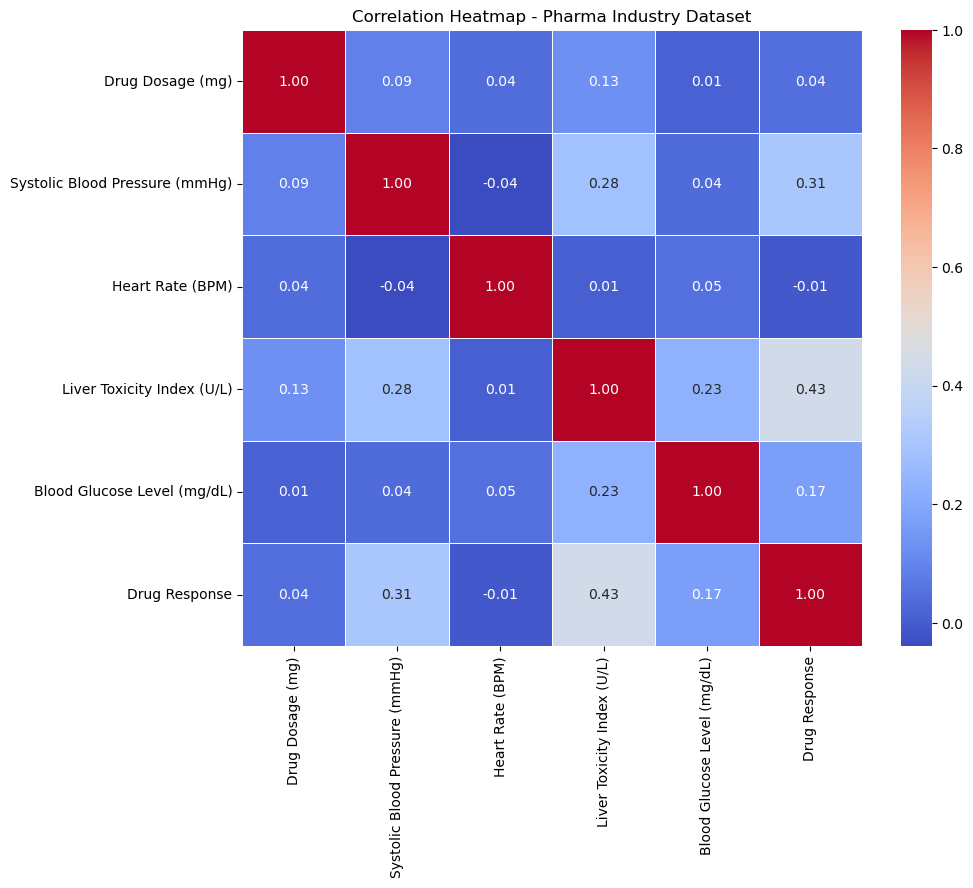

In [1]:
# Task 1: Exploratory Data Analysis (EDA)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset
df = pd.read_csv('Pharma_Industry.csv')
print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

# 2. Summary Statistics
print("\n--- Summary Statistics ---")
print(df.describe())

# 3. Distributions & Correlations
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap - Pharma Industry Dataset')
plt.show()

In [8]:
#Task 2: Data Preprocessing
# Task 2: Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop(columns=['Drug Response'])
y = df['Drug Response']

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- Add these print statements to see outputs ---
print("Preprocessing completed successfully!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("First 2 scaled training rows:\n", X_train_scaled[:2])

Preprocessing completed successfully!
X_train shape: (400, 5)
X_test shape: (100, 5)
First 2 scaled training rows:
 [[-0.01028519 -1.10756998 -0.32832269 -0.25029362 -0.16230813]
 [ 0.35490662  0.07720715  0.12812207  0.05137576  0.16836633]]


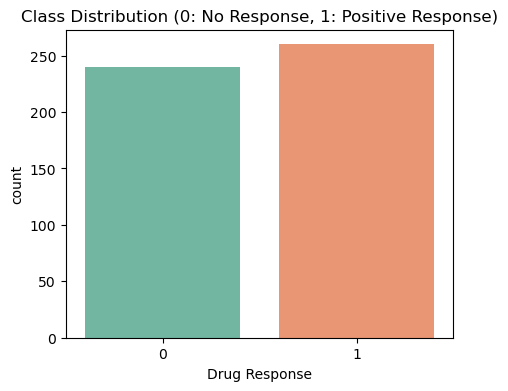

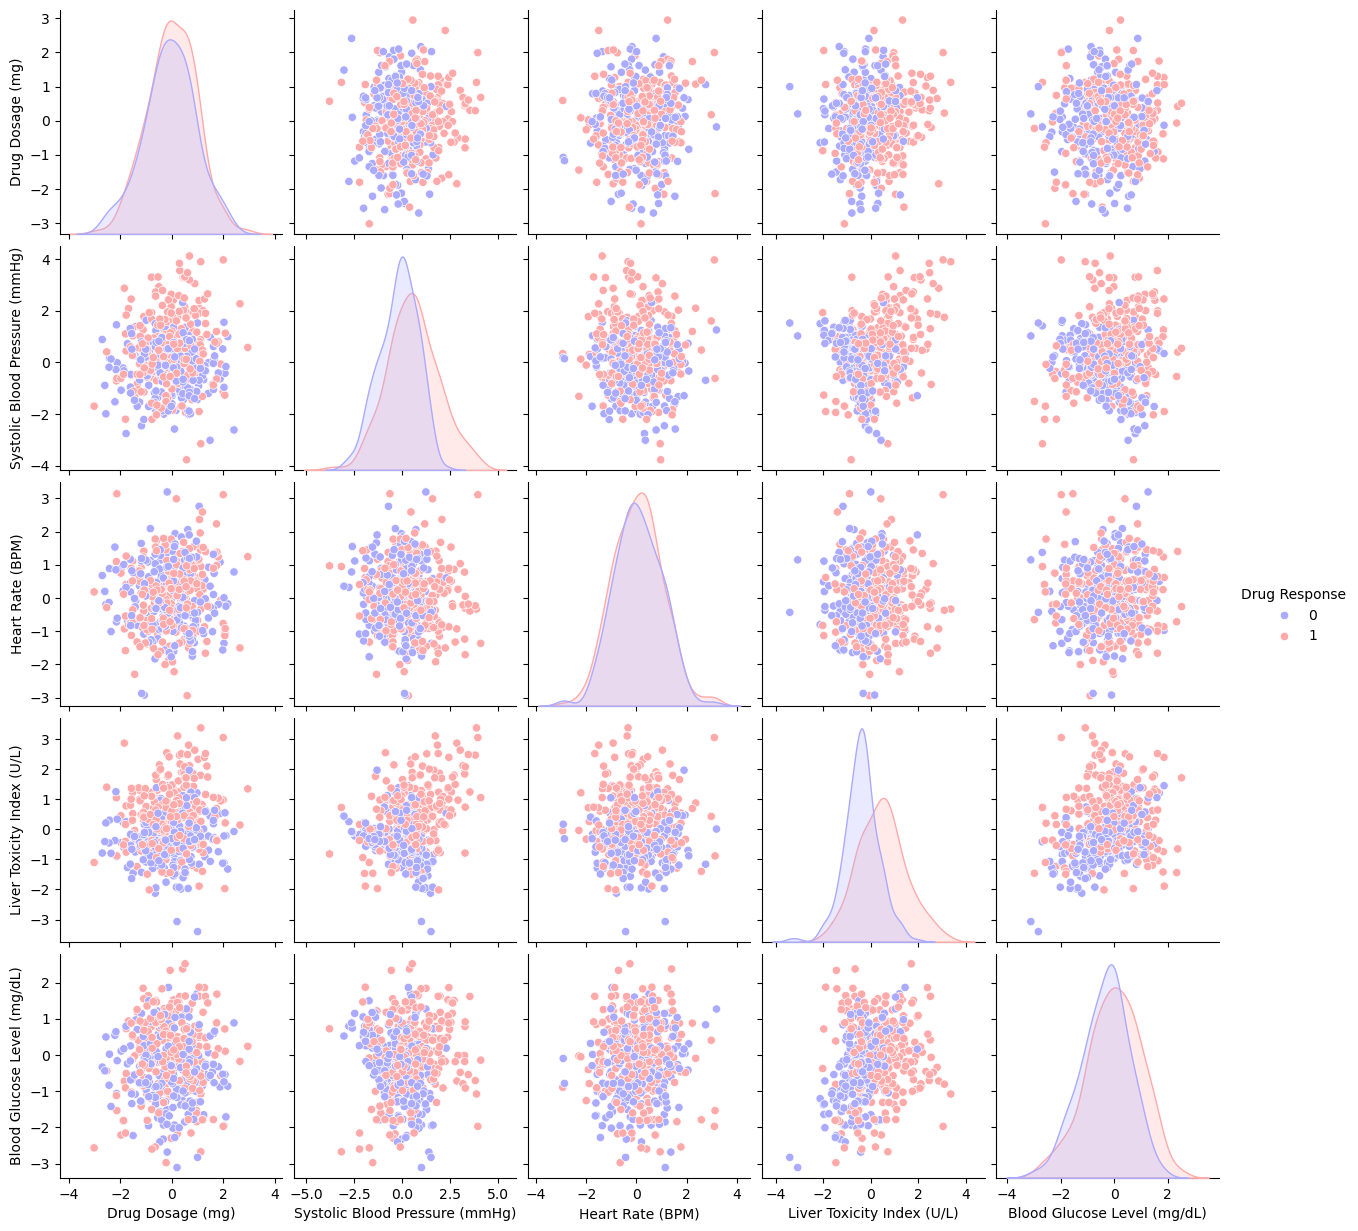

In [7]:
# Task 3: Data Visualization 
# Visualize class distribution
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize class distribution (fixed for newer Seaborn versions)
plt.figure(figsize=(5, 4))
sns.countplot(x='Drug Response', hue='Drug Response', data=df, palette='Set2')
plt.legend([], [], frameon=False)  # Cleanly hides the legend box
plt.title('Class Distribution (0: No Response, 1: Positive Response)')
plt.show()

# Pairplot to visualize feature relationships colored by response
sns.pairplot(df, hue='Drug Response', palette='bwr', diag_kind='kde')
plt.show()

Accuracy:  0.7700
Precision: 0.7544
Recall:    0.8269
F1-Score:  0.7890


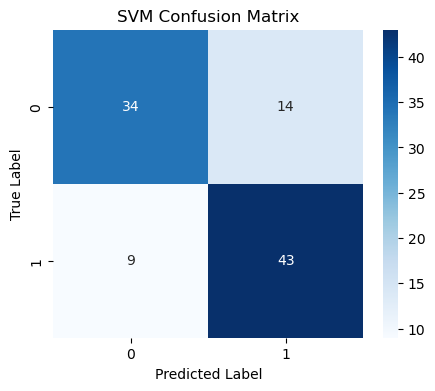

In [4]:
# Task 4 & 5: SVM Implementation & Evaluation
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Train SVM Model (RBF Kernel)
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# 2. Predictions & Evaluation
y_pred = svm_model.predict(X_test_scaled)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

# Visualize Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('SVM Confusion Matrix')
plt.show()

In [5]:
#Task 6: Parameter Tuning and Optimization
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'kernel': ['linear', 'rbf', 'poly']
}

grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='f1')
grid_search.fit(X_train_scaled, y_train)

print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best Cross-Validation F1-Score: {grid_search.best_score_:.4f}")

Best Hyperparameters: {'C': 1, 'gamma': 1, 'kernel': 'rbf'}
Best Cross-Validation F1-Score: 0.7716


In [6]:
#Task 7: Comparison, Analysis & Discussion
#1. Kernel Comparison Summary
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
comparison_results = []

for k in kernels:
    model = SVC(kernel=k, random_state=42)
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    comparison_results.append({
        'Kernel': k,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds, zero_division=0),
        'F1-Score': f1_score(y_test, preds, zero_division=0)
    })

print(pd.DataFrame(comparison_results))

    Kernel  Accuracy  Precision    Recall  F1-Score
0   linear      0.72   0.760870  0.673077  0.714286
1     poly      0.65   0.666667  0.653846  0.660194
2      rbf      0.77   0.754386  0.826923  0.788991
3  sigmoid      0.73   0.755102  0.711538  0.732673
